In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
#upload file from your local system
#import files Module
from google.colab import files
#upload file from local system
uploaded = files.upload()

# Dynamically get the key (filename) of the uploaded file as a string
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)
print(df.head())

Saving taxis.csv to taxis (1).csv
                pickup              dropoff  passengers  distance  fare   tip  \
0  2019-03-23 20:21:09  2019-03-23 20:27:24           1      1.60   7.0  2.15   
1  2019-03-04 16:11:55  2019-03-04 16:19:00           1      0.79   5.0  0.00   
2  2019-03-27 17:53:01  2019-03-27 18:00:25           1      1.37   7.5  2.36   
3  2019-03-10 01:23:59  2019-03-10 01:49:51           1      7.70  27.0  6.15   
4  2019-03-30 13:27:42  2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan   

In [28]:
#Import libraries and load dataset
# Set visualization style
sns.set_theme(style="whitegrid")

# Load dataset
df = sns.load_dataset("taxis")

# Display first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [29]:
# Understand the dataset

# Dataset information
print("Dataset Shape:", df.shape)

# Column information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Dataset Shape: (6433, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223616,2019-03-16 08:45:49.491217408,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


Missing Values:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [30]:
# Handle missing values

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(
    include=np.number
).columns

categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

# Fill numerical missing values using median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values using mode
for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Remove rows missing critical values
df.dropna(subset=["pickup", "fare"], inplace=True)

# Verify missing values
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("Cleaned Dataset Shape:", df.shape)

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Cleaned Dataset Shape: (6433, 14)


In [31]:
#Convert pickup column into datetime

df["pickup"] = pd.to_datetime(
    df["pickup"],
    errors="coerce"
)

# Remove rows with invalid pickup timestamps
df.dropna(subset=["pickup"], inplace=True)

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


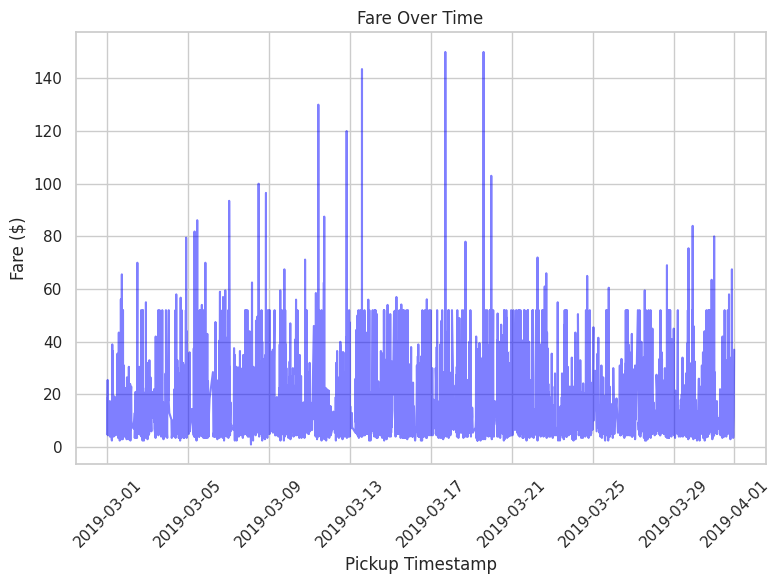

In [ ]:
# 2. Visualizations using Matplotlib
# 1. Line Chart Fare Over Time

plt.figure(figsize=(8, 6))

fare_time = df.sort_values("pickup")

plt.plot(
    fare_time["pickup"],
    fare_time["fare"],
    color="blue",
    alpha=0.5
)

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

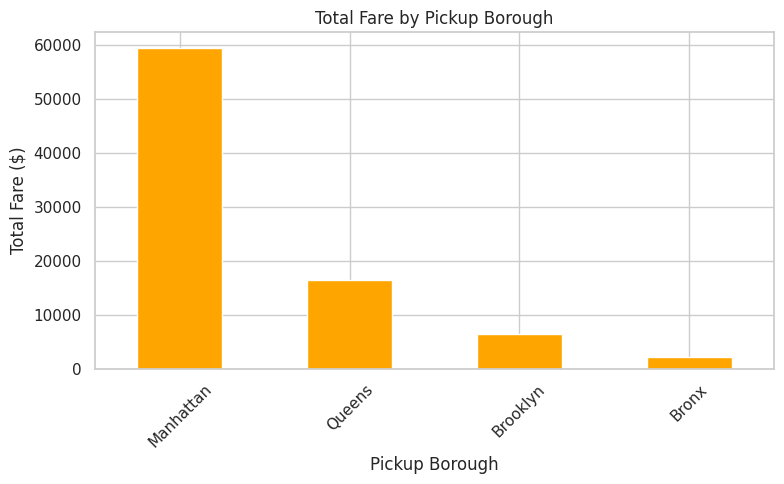

In [ ]:
#2. Bar Chart – Total Fare by Pickup Borough

borough_fare = df.groupby(
    "pickup_borough"
)["fare"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

borough_fare.plot(
    kind="bar",
    color="orange"
)

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

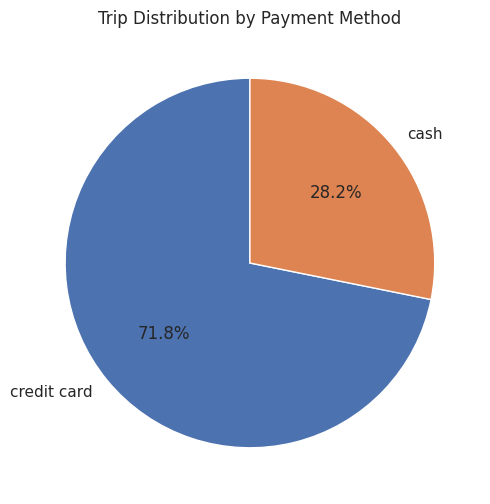

In [ ]:
# 3. Pie Chart Payment Method Distribution

payment_counts = df["payment"].value_counts()

plt.figure(figsize=(7, 6))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Trip Distribution by Payment Method")
plt.show()

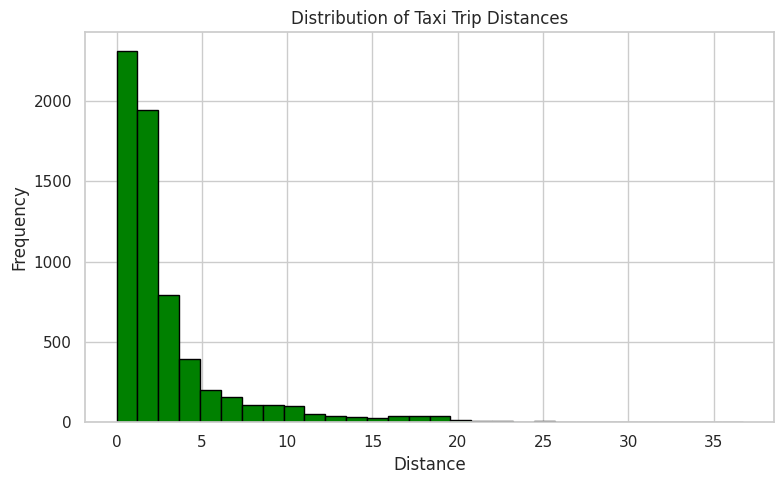

In [ ]:
 # 4. Histogram  Distance Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df["distance"],
    bins=30,
    color="green",
    edgecolor="black"
)

plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

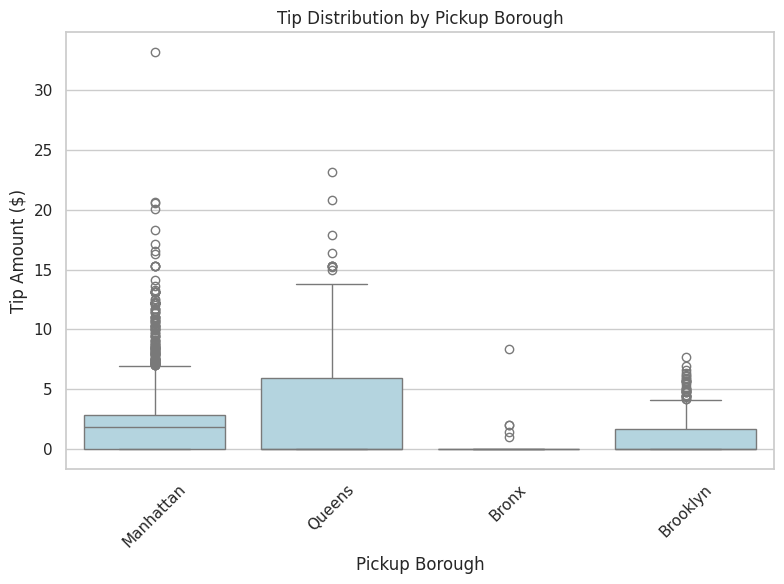

In [ ]:
 # 5. Box Plot – Tip Distribution by Pickup Borough

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="pickup_borough",
    y="tip",
    color="lightblue"
)

plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

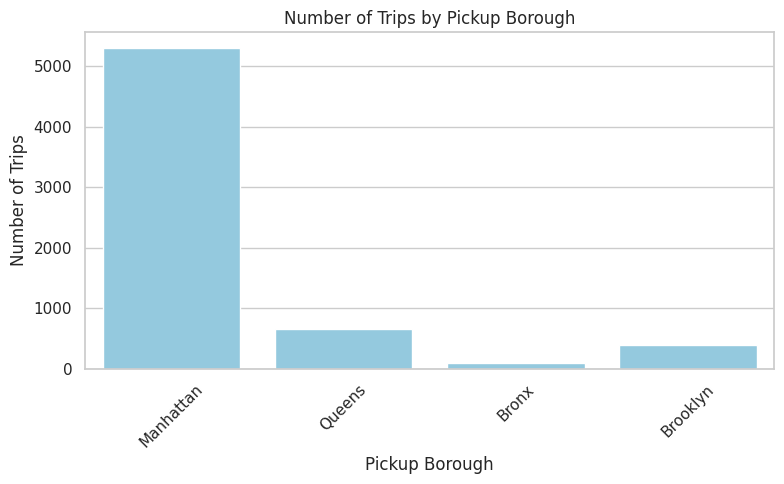

In [ ]:
# 3. Visualizations using Seaborn
# 6. Count Plot Trips by Pickup Borough

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="pickup_borough",
    color="skyblue"
)

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

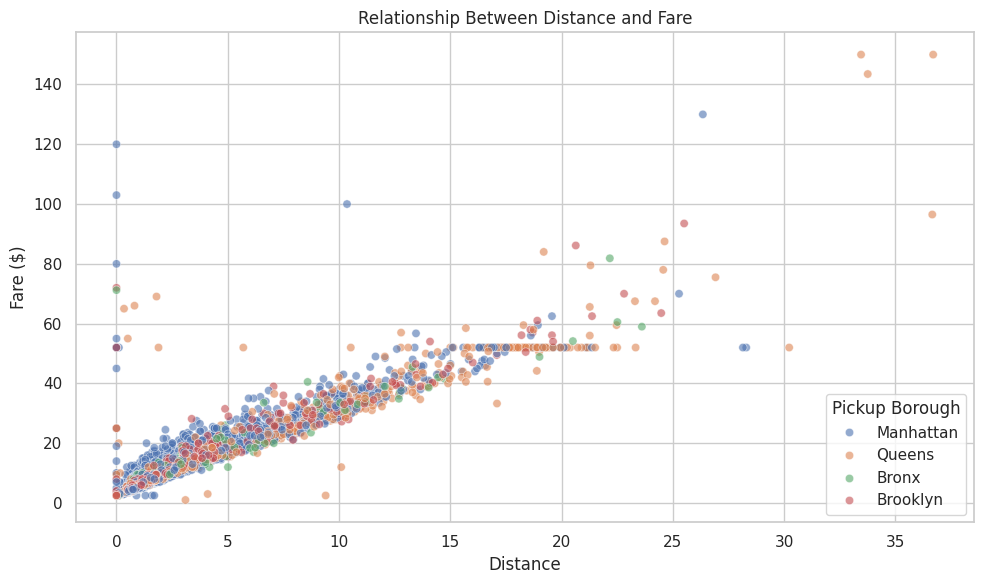

In [ ]:
# 7. Scatter Plot Distance vs Fare


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.6
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare ($)")
plt.legend(title="Pickup Borough")

plt.tight_layout()
plt.show()

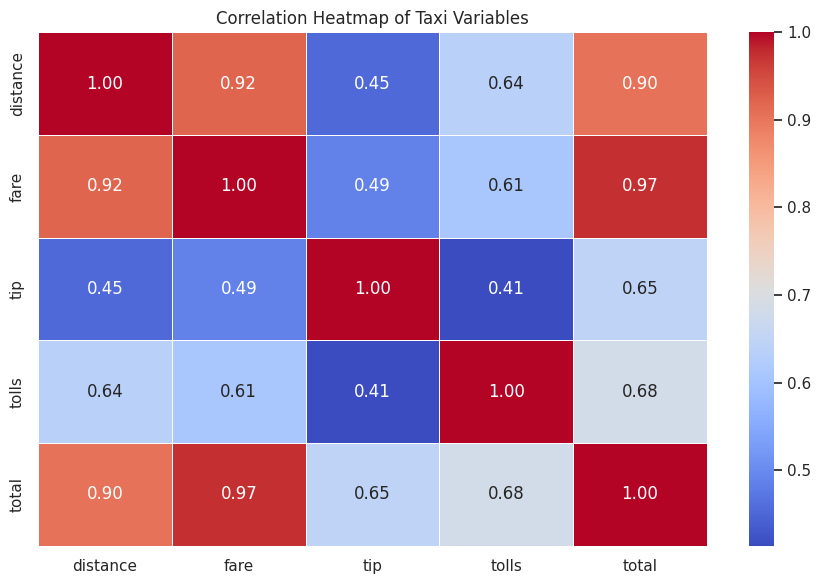

In [ ]:
# 8. Heatmap – Correlation Matrix

corr_cols = [
    "distance",
    "fare",
    "tip",
    "tolls",
    "total"
]

correlation = df[corr_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Taxi Variables")
plt.tight_layout()
plt.show()

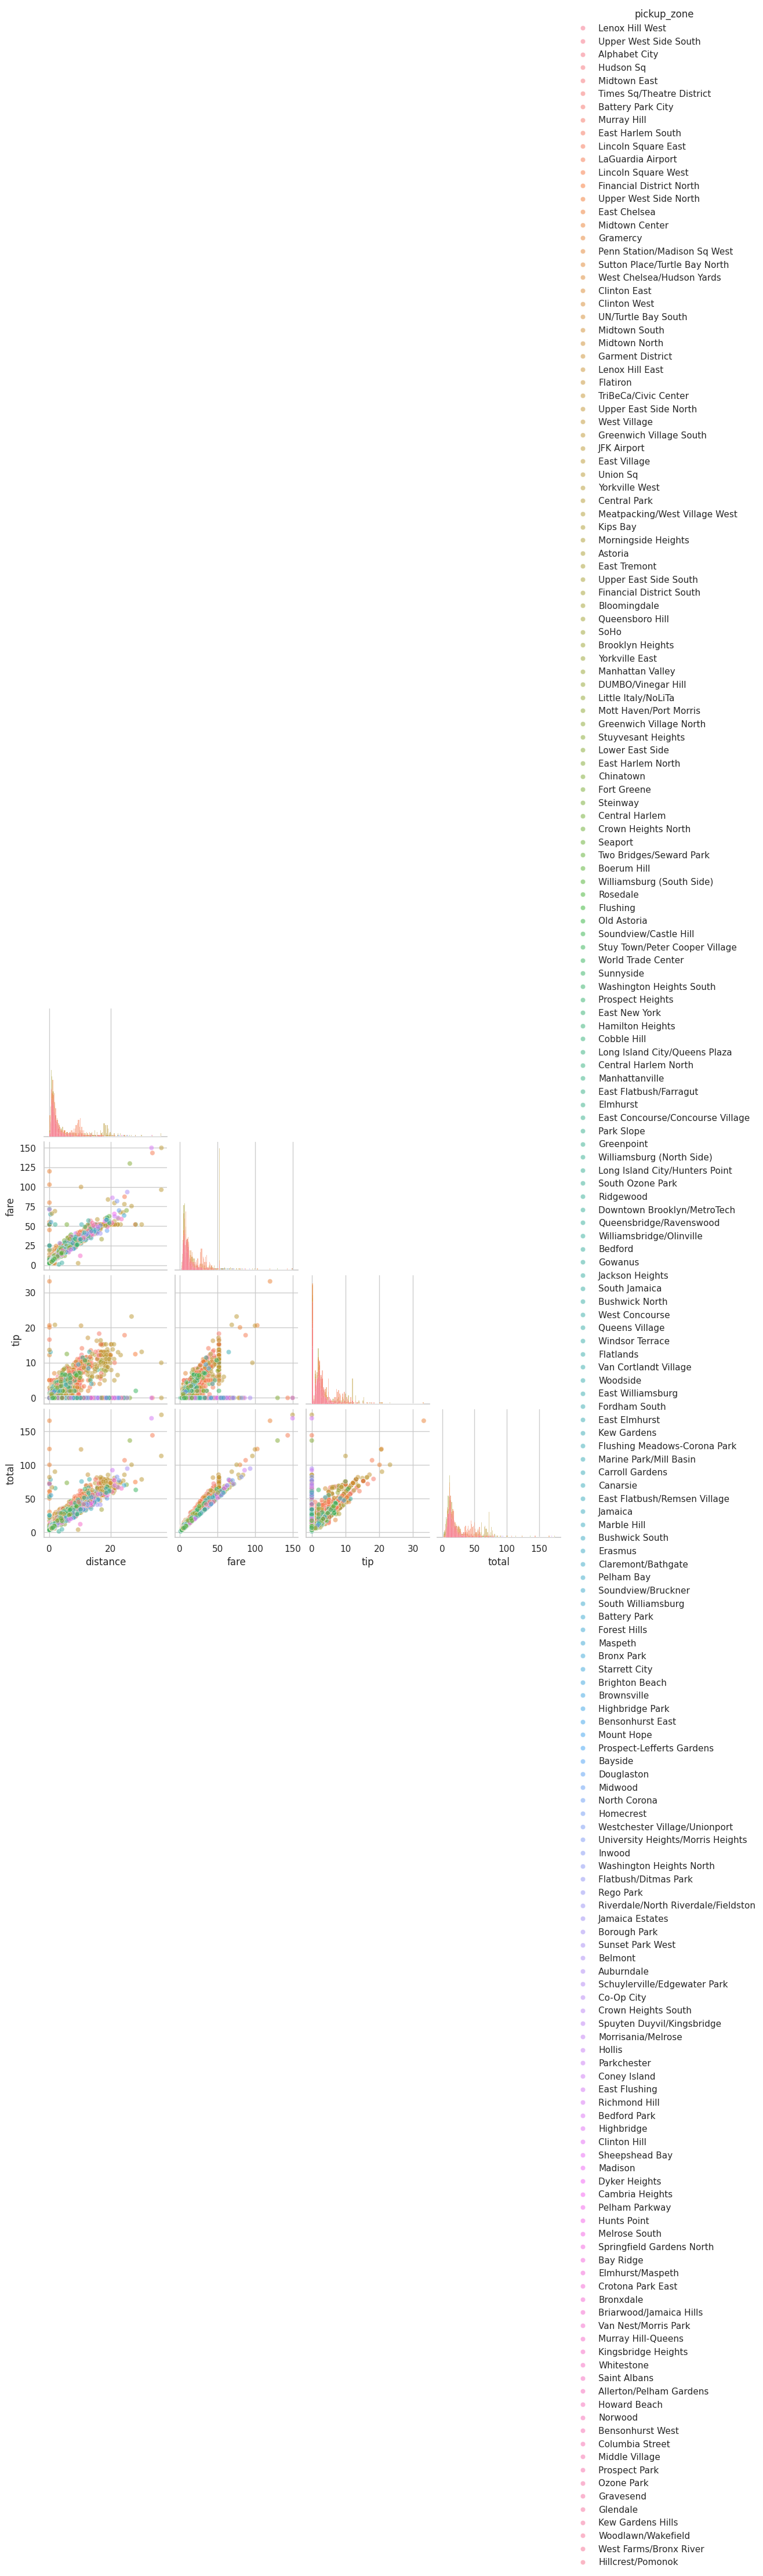

In [ ]:
#  9. Pair Plot – Pairwise Relationships

pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

sns.pairplot(
    pair_data,
    hue="pickup_zone",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5}
)

plt.show()

/tmp/ipykernel_1035/2323936145.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


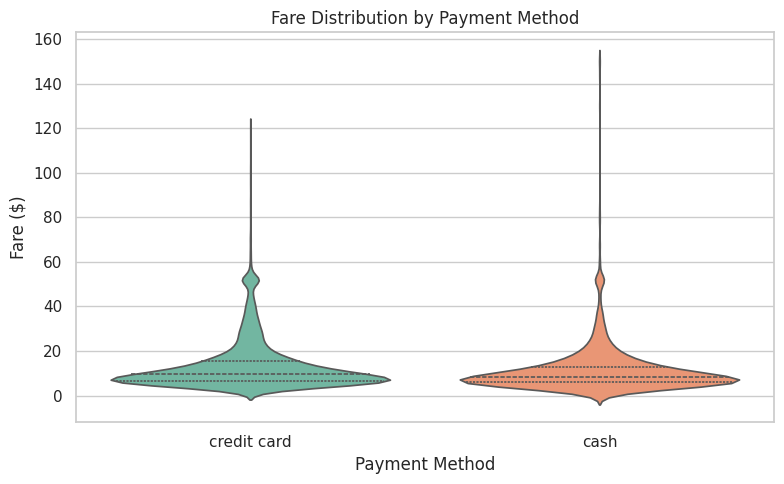

In [ ]:
# 10. Violin Plot – Fare by Payment Method


plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare",
    inner="quartile",
    palette="Set2"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")

plt.tight_layout()
plt.show()


In [ ]:
#4. Additional Analysis
#Run this cell to generate useful statistics for your report.

print("TAXI DATA ANALYSIS REPORT")
print("=" * 40)

print("1. Total Number of Trips:")
print(len(df))

print("2. Average Fare:")
print(round(df["fare"].mean(), 2))

print("3. Average Distance:")
print(round(df["distance"].mean(), 2))

print("4. Average Tip:")
print(round(df["tip"].mean(), 2))

print("5. Most Common Payment Method:")
print(df["payment"].mode()[0])

print("6. Most Popular Pickup Borough:")
print(df["pickup_borough"].value_counts().idxmax())

print("7. Borough with Highest Total Fare:")
print(df.groupby("pickup_borough")["fare"].sum().idxmax())

print("8. Distance and Fare Correlation:")
print(round(df["distance"].corr(df["fare"]), 2))

TAXI DATA ANALYSIS REPORT
1. Total Number of Trips:
6433
2. Average Fare:
13.09
3. Average Distance:
3.02
4. Average Tip:
1.98
5. Most Common Payment Method:
credit card
6. Most Popular Pickup Borough:
Manhattan
7. Borough with Highest Total Fare:
Manhattan
8. Distance and Fare Correlation:
0.92
